# Intelligent Agents: Reflex-Based Agents for GridHunt

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and the hunter and the monster move on this grid. A hunter catches the monster if she/he moves on the same square the monster currently occupies. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunter are randomly placed in the arena environment. The hunter and the monster
    can move around, but cannot leave the arena.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena but only gets the monster location when it stops and listens.

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [1]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_agent_function, 
                      monster_agent_function, 
                      n = 30, max_steps = 100, 
                      visualize = False, animation = False):
    """
    Simulate an arena where a hunter agent tries to catch a monster agent.

    Parameters:
    hunter_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_pos = np.random.randint(0, n-1, size=2)
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step+1}: Hunter is at '{hunter_pos}'; Monster is at '{monster_pos}'")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_pos[0], hunter_pos[1]] = 'H'
        if np.array_equal(hunter_pos, monster_pos):
            arena[monster_pos[0], monster_pos[1]] = '*'
        print("\n".join("".join(row) for row in arena))

    # run the environment
    hunter_action = None  # Initialize hunter_action to None for the first step
    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_pos, monster_pos):
            if visualize:
                print(f"Hunter caught the monster in {step} steps!")
            return step
        
        # Get next move from monster agent function
        monster_action = monster_agent_function(hunter_pos, monster_pos)
        
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function. The monster's position is only provided 
        # if the hunter chose 'listen' as the previous action.
        if hunter_action == 'listen':
            monster_pos_instrument = monster_pos
        else: 
            monster_pos_instrument = None
        
        hunter_action = hunter_agent_function(hunter_pos, monster_pos_instrument)
        
        if hunter_action == 'listen':
            pass
        elif hunter_action == 'teleport':
            hunter_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_pos = move(hunter_action, hunter_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter chose action '{hunter_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Hunter failed to catch the monster in {max_steps} steps.")
    
    return np.nan

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [2]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(hunter_pos, monster_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [3]:
actions = ["north", "east", "west", "south", "teleport", "listen"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [4]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [5]:
simple_randomized_hunter_agent_function([0,0], None)

np.str_('north')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [6]:
arena_environment(simple_randomized_hunter_agent_function, 
                  monster_agent_function_simple, 
                  n=5, max_steps=10, visualize=True, animation=False)

Step 1: Hunter is at '[3 0]'; Monster is at '[0 2]'
..M..
.....
.....
H....
.....
Hunter chose action 'west'
Monster chose action 'south'


Step 2: Hunter is at '[3 0]'; Monster is at '[1 2]'
.....
..M..
.....
H....
.....
Hunter chose action 'teleport'
Monster chose action 'stay'


Step 3: Hunter is at '[2 3]'; Monster is at '[1 2]'
.....
..M..
...H.
.....
.....
Hunter chose action 'teleport'
Monster chose action 'west'


Step 4: Hunter is at '[2 1]'; Monster is at '[1 1]'
.....
.M...
.H...
.....
.....
Hunter chose action 'south'
Monster chose action 'north'


Step 5: Hunter is at '[3 1]'; Monster is at '[0 1]'
.M...
.....
.....
.H...
.....
Hunter chose action 'south'
Monster chose action 'north'


Step 6: Hunter is at '[4 1]'; Monster is at '[0 1]'
.M...
.....
.....
.....
.H...
Hunter chose action 'teleport'
Monster chose action 'west'


Step 7: Hunter is at '[1 0]'; Monster is at '[0 0]'
M....
H....
.....
.....
.....
Hunter chose action 'listen'
Monster chose action 'south'


Step 8:

7

**Note for VS Code:** View as scrollable element to see the complete output.

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $10 \times 10$ arena.  

In [7]:
steps = [arena_environment(simple_randomized_hunter_agent_function, monster_agent_function_simple, n=10, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[20, nan, 42, 12, 9, 85, nan, 54, 21, nan, 28, nan, nan, nan, 25, nan, nan, nan, nan, 56, 33, 77, 74, nan, 32, 56, 12, nan, nan, nan, 10, 87, 19, nan, 52, 27, 82, 60, nan, nan, nan, nan, 43, nan, nan, 13, nan, 55, 46, nan, nan, nan, 26, nan, nan, 11, 78, nan, 65, 12, 56, 55, nan, nan, 65, nan, nan, 0, nan, nan, nan, nan, nan, 66, 10, 7, nan, nan, nan, nan, 38, nan, 51, nan, 98, 67, nan, nan, 84, 68, 44, 89, 47, 95, nan, 1, 98, nan, nan, nan]


We just got a list with the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results. `nan` means that the hunter was not able to catch the monster. How many times did that happen? To answer how well the hunter did when it caught the monster, we just average the numbers that are not `nan`. 

In [8]:
print (f"Hunter failed {np.sum(np.isnan(steps))} times.")
print (f"Average steps to catch the monster over {np.sum(~np.isnan(steps))} successful runs: {round(np.nanmean(steps), 2)}")

Hunter failed 49 times.
Average steps to catch the monster over 51 successful runs: 46.29


This in not a very good agent. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and make it into a model-based reflex agent. It should use listen to get the monster's location and then move towards the monster. To do that it needs to remember the monster's location. This memory makes it model-based. Here is HOWTO: How to Store State Information in the Agent.

### Thiết kế agent

Hunter là **model-based reflex agent**. Nó không thấy quái vật trừ khi vừa `listen`, và quái vật tiếp tục di chuyển, nên nó phải **nhớ** (mô hình nội bộ) vị trí quái vật nghe được lần cuối.

| Biến trạng thái | Ý nghĩa |
|---|---|
| `known` | vị trí quái vật nghe được lần cuối (hoặc `None` nếu chưa biết) |
| `moves_left` | số bước còn lại được phép đi theo `known` trước khi nghe lại |
| `teleport_next` | đã quyết định teleport ở lượt này |

**Luật hành động**

1. Chưa biết vị trí quái vật (`known is None`) → `listen`.
2. Vừa nghe được vị trí mới → cập nhật `known` và tính ngân sách di chuyển `moves_left = max(1, 0.7 × khoảng cách Manhattan)`. Quái vật chỉ di chuyển ngẫu nhiên ~0,5 ô/bước nên đi thẳng theo thông tin cũ là hợp lý trong một khoảng ngắn; thông tin càng cũ càng kém tin cậy nên nghe lại khi đã đi phần lớn quãng đường.
3. Nếu khoảng cách $> n/2$ → `teleport` (rơi ngẫu nhiên có khoảng cách kỳ vọng tới quái vật nhỏ hơn quãng đường phải đi), sau đó `listen` lại.
4. Nếu `moves_left > 0` → đi một bước theo trục có chênh lệch lớn hơn tới `known` (giảm khoảng cách Manhattan).
5. Hết `moves_left`, hoặc đã tới `known` mà chưa thấy quái vật → `listen`.

Hàm được tạo bởi `make_hunter(n)` để mỗi ván có trạng thái mới; hàm trả về giữ nguyên giao diện `(hunter_location, monster_location)` mà môi trường yêu cầu.

In [9]:
def make_hunter(n, use_teleport=True, listen_fraction=0.7):
    """Create a model-based hunter with fresh internal state (one per game)."""
    state = {"known": None, "moves_left": 0, "teleport_next": False}

    def hunter(hunter_location, monster_location):
        pos = np.asarray(hunter_location)

        # update the model when the environment delivered a listen result
        if monster_location is not None:
            state["known"] = np.array(monster_location)          # copy: the array is reused by the env
            dist = np.abs(state["known"] - pos).sum()
            state["moves_left"] = max(1, int(listen_fraction * dist))
            state["teleport_next"] = use_teleport and dist > n / 2

        if state["teleport_next"]:                               # far away: jump, then re-listen
            state.update(teleport_next=False, moves_left=0, known=None)
            return "teleport"

        if state["known"] is None or state["moves_left"] <= 0:   # information too old / none yet
            state["known"] = None
            return "listen"

        diff = state["known"] - pos
        if not diff.any():                                       # reached the remembered spot: monster moved
            state["known"] = None
            return "listen"

        state["moves_left"] -= 1
        if abs(diff[0]) >= abs(diff[1]):                         # reduce the larger coordinate gap first
            return "south" if diff[0] > 0 else "north"
        return "east" if diff[1] > 0 else "west"

    return hunter

Demo: một ván nhỏ 8×8 để xem hunter hoạt động (đầu ra ngắn).

In [10]:
np.random.seed(5)
arena_environment(make_hunter(8), monster_agent_function_simple, n=8, max_steps=30, visualize=True)

Step 1: Hunter is at '[5 6]'; Monster is at '[3 6]'
........
........
........
......M.
........
......H.
........
........
Hunter chose action 'listen'
Monster chose action 'west'


Step 2: Hunter is at '[5 6]'; Monster is at '[3 5]'
........
........
........
.....M..
........
......H.
........
........
Hunter chose action 'north'
Monster chose action 'stay'


Step 3: Hunter is at '[4 6]'; Monster is at '[3 5]'
........
........
........
.....M..
......H.
........
........
........
Hunter chose action 'north'
Monster chose action 'north'


Step 4: Hunter is at '[3 6]'; Monster is at '[2 5]'
........
........
.....M..
......H.
........
........
........
........
Hunter chose action 'listen'
Monster chose action 'south'


Step 5: Hunter is at '[3 6]'; Monster is at '[3 5]'
........
........
........
.....MH.
........
........
........
........
Hunter chose action 'west'
Monster chose action 'west'


Step 6: Hunter is at '[3 5]'; Monster is at '[3 4]'
........
........
........
....MH..

9

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

Chạy 500 ván cho mỗi cấu hình (nhiều hơn mức tối thiểu 100 để số liệu ổn định). Với 10×10 dùng `max_steps=100`; với 30×30 dùng cả `max_steps=100` (giới hạn mặc định) và `max_steps=200`. So sánh: hunter ngẫu nhiên, hunter model-based **không teleport** và hunter model-based **có teleport**.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

def experiment(make_agent, n, max_steps, runs=500):
    steps = np.array([arena_environment(make_agent(n), monster_agent_function_simple, n=n, max_steps=max_steps)
                      for _ in range(runs)], dtype=float)
    ok = ~np.isnan(steps)
    return dict(success_rate=ok.mean(), mean_steps=np.mean(steps[ok]) if ok.any() else np.nan, steps=steps[ok])

hunters = {
    "Random": lambda n: simple_randomized_hunter_agent_function,
    "Model-based (no teleport)": lambda n: make_hunter(n, use_teleport=False),
    "Model-based (teleport)": lambda n: make_hunter(n, use_teleport=True),
}
configs = [(10, 100), (30, 100), (30, 200)]

np.random.seed(42)
rows, samples = [], {}
for n, ms in configs:
    for name, mk in hunters.items():
        r = experiment(mk, n, ms)
        samples[(n, ms, name)] = r["steps"]
        rows.append({"arena": f"{n}x{n}", "max_steps": ms, "hunter": name,
                     "success rate": f"{100 * r['success_rate']:.1f}%", "mean steps (successes)": round(r["mean_steps"], 1)})
pd.DataFrame(rows)

,arena,max_steps,hunter,success rate,mean steps (successes)
0,10x10,100,Random,51.0%,41.7
1,10x10,100,Model-based (no teleport),100.0%,10.1
2,10x10,100,Model-based (teleport),100.0%,9.8
3,30x30,100,Random,8.2%,52.5
4,30x30,100,Model-based (no teleport),100.0%,24.5
5,30x30,100,Model-based (teleport),100.0%,18.5
6,30x30,200,Random,16.6%,86.7
7,30x30,200,Model-based (no teleport),100.0%,24.5
8,30x30,200,Model-based (teleport),100.0%,18.1


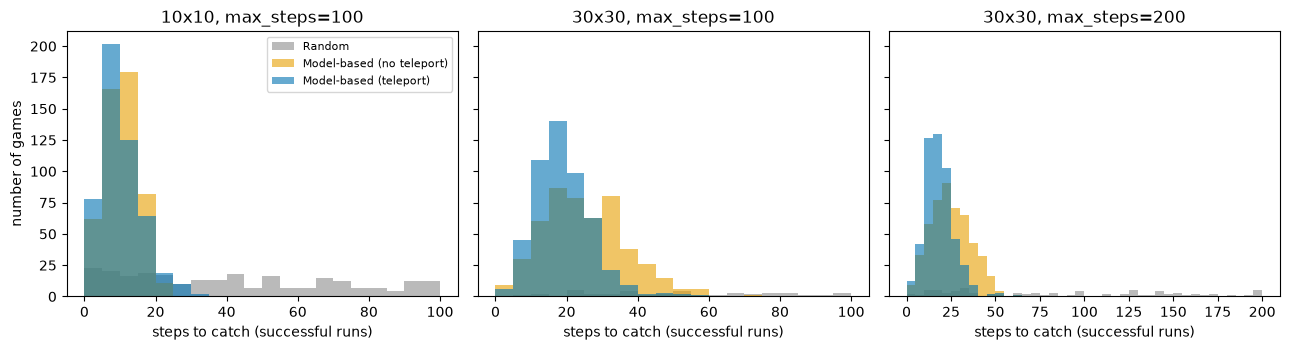

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
colors = ["#8c8c8c", "#e69f00", "#0072b2"]
for ax, (n, ms) in zip(axes, configs):
    for (name, _), c in zip(hunters.items(), colors):
        ax.hist(samples[(n, ms, name)], bins=np.arange(0, ms + 5, 5), alpha=0.6, color=c, label=name)
    ax.set_title(f"{n}x{n}, max_steps={ms}"); ax.set_xlabel("steps to catch (successful runs)")
axes[0].set_ylabel("number of games"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

### Chiến lược của hunter và lý do nó hiệu quả

Hunter dùng `listen` để có vị trí quái vật, **ghi nhớ** vị trí đó (trạng thái `known`) rồi đi theo trục có chênh lệch lớn hơn để giảm khoảng cách Manhattan. Nó chỉ nghe lại sau khi đã đi khoảng 70% quãng đường tới vị trí đã nhớ (`listen_fraction = 0.7`), và bỏ nghe lại nếu tới nơi mà quái vật đã đi chỗ khác.

Vì sao hiệu quả: quái vật đứng yên 50% thời gian và mỗi lần chỉ di chuyển 1 ô, nên vị trí cũ vẫn rất gần vị trí thật trong vài bước; hunter mất một bước `listen` nhưng đổi lại các bước sau đều có hướng đi. Ta đã thử `listen_fraction` khác: nghe mỗi bước (mỗi lần chỉ đi 1 ô) tốn ≈ 2 bước cho 1 ô di chuyển (≈ 12,6 bước ở 10×10 so với ≈ 9,6), còn nghe quá thưa thì đi theo thông tin cũ. Tỉ lệ 0,7 nằm trong vùng gần tối ưu. Kết quả: **100% thành công** và trung bình ≈ 10 bước ở 10×10 (hunter ngẫu nhiên: 51% thành công, ≈ 42 bước), và ≈ 18–25 bước ở 30×30 (hunter ngẫu nhiên: chỉ 8% thành công với 100 bước, 17% với 200 bước).

### Teleport

Có dùng, nhưng **chỉ khi hunter ở xa quái vật** (khoảng cách Manhattan $> n/2$). Teleport đưa hunter tới một ô ngẫu nhiên, tốn 1 bước; vị trí mới có khoảng cách kỳ vọng tới quái vật xấp xỉ $2n/3$ *độc lập* với vị trí hiện tại. Khi khoảng cách hiện tại lớn hơn mức đó thì nhảy có lợi (kỳ vọng ngắn hơn, đổi lại phải nghe lại vì mất đi thông tin), còn khi hunter đang ở gần quái vật thì teleport gần như chắc chắn làm mất lợi thế. Kết quả thực nghiệm: ở 30×30 teleport giảm số bước trung bình từ 24,5 xuống ≈ 18 (giảm ≈ 26%), trong khi ở 10×10 chỉ cải thiện rất ít (10,1 → 9,8) vì hầu như không có trường hợp khoảng cách vượt $n/2$ đủ nhiều để bù chi phí.

### Ảnh hưởng của kích thước arena

Arena càng lớn thì khoảng cách trung bình ban đầu (≈ $2n/3$) và số bước cần thiết càng tăng gần tuyến tính theo $n$ (≈ 10 bước ở 10×10 → ≈ 25 bước ở 30×30 khi không teleport). Hunter ngẫu nhiên suy giảm rất nhanh: từ 51% xuống 8% thành công vì xác suất tình cờ va chạm giảm theo diện tích $n^2$. Hunter model-based vẫn thành công 100% với giới hạn 100 bước ở cả hai kích thước, nhưng với các arena lớn hơn nữa cần tăng `max_steps` hoặc dùng teleport.

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

Quái vật hiện chỉ đi ngẫu nhiên và đứng yên 50% thời gian nên rất dễ bị bắt. Agent của quái vật nhận được vị trí của hunter (`hunter_pos`) nên có thể được cải thiện bằng các luật:

* **Chạy trốn:** khi hunter ở gần (khoảng cách Manhattan nhỏ), chọn hướng đi làm *tăng* khoảng cách tới hunter; khi hunter ở xa thì đứng yên để không tự bộc lộ.
* **Tránh góc và tường:** bị dồn vào góc thì không còn đường thoát, nên ưu tiên hướng có nhiều ô thoáng hơn (nhiều nước đi hợp lệ).
* **Khó đoán:** thêm nhiễu ngẫu nhiên (ví dụ 20–30% nước đi ngẫu nhiên) để hunter không thể dự đoán vị trí khi đã `listen`, khiến thông tin nghe được trở nên lỗi thời nhanh hơn.
* **Khai thác hạn chế của hunter:** hunter mất 1 bước cho mỗi `listen`, nên quái vật luôn di chuyển liên tục khi hunter đang đến gần sẽ có tốc độ hiệu dụng cao hơn hunter, khiến hunter chỉ bắt được khi dồn vào tường/góc. Cần cân đối: nếu quái vật quá nhanh thì hunter không bao giờ bắt được.

# More Work (Optional)

Here are some ideas:

* Implement a better monster agent function and perform experiments
* Change the environment so multiple hunters can hunt the monster.
* Give the hunter a new action that shoots an arrow in a specific direction. 
  The arrow can go a maximum of 5 squares. If the hunter hits the monster, then it wins.